In [1]:
import pandas as pd

df = pd.read_csv(
    "Algerian_forest_fires_dataset_UPDATE.csv",
    skiprows=1
)

print(df.head())

  Day Month  Year Temperature  Relative Humidity Wind Speed Rain   \
0  01    06  2012          29                 57         18     0   
1  02    06  2012          29                 61         13   1.3   
2  03    06  2012          26                 82         22  13.1   
3  04    06  2012          25                 89         13   2.5   
4  05    06  2012          27                 77         16     0   

  Fine Fuel Moisture Code Duff Moisture Code Drought Code  \
0                    65.7                3.4          7.6   
1                    64.4                4.1          7.6   
2                    47.1                2.5          7.1   
3                    28.6                1.3          6.9   
4                    64.8                  3         14.2   

  Initial Spread Index Buildup Index Fire Weather Index    Classes    
0                  1.3           3.4                0.5  not fire     
1                    1           3.9                0.4  not fire     
2    

In [2]:
df.columns = df.columns.str.strip()

print(df.columns)

Index(['Day', 'Month', 'Year', 'Temperature', 'Relative Humidity',
       'Wind Speed', 'Rain', 'Fine Fuel Moisture Code', 'Duff Moisture Code',
       'Drought Code', 'Initial Spread Index', 'Buildup Index',
       'Fire Weather Index', 'Classes'],
      dtype='object')


In [3]:
df = df.apply(
    lambda x: x.str.strip() if x.dtype == "object" else x
)

print(df["Classes"].value_counts())

Classes
fire        137
not fire    106
Classes       1
Name: count, dtype: int64


In [4]:
numeric_columns = [
    "Day",
    "Month",
    "Year",
    "Temperature",
    "Relative Humidity",
    "Wind Speed",
    "Rain",
    "Fine Fuel Moisture Code",
    "Duff Moisture Code",
    "Drought Code",
    "Initial Spread Index",
    "Buildup Index",
    "Fire Weather Index"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [5]:
print("Rows and Columns:", df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

Rows and Columns: (247, 14)

Column Data Types:
Day                        float64
Month                      float64
Year                       float64
Temperature                float64
Relative Humidity          float64
Wind Speed                 float64
Rain                       float64
Fine Fuel Moisture Code    float64
Duff Moisture Code         float64
Drought Code               float64
Initial Spread Index       float64
Buildup Index              float64
Fire Weather Index         float64
Classes                     object
dtype: object


In [6]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Day                        3
Month                      3
Year                       3
Temperature                3
Relative Humidity          3
Wind Speed                 3
Rain                       3
Fine Fuel Moisture Code    3
Duff Moisture Code         3
Drought Code               4
Initial Spread Index       3
Buildup Index              3
Fire Weather Index         4
Classes                    3
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


In [8]:
print("\nClass Distribution:")
print(df["Classes"].value_counts())


Class Distribution:
Classes
fire        137
not fire    106
Classes       1
Name: count, dtype: int64


In [9]:
print("\nClass Percentage:")
print(df["Classes"].value_counts(normalize=True) * 100)


Class Percentage:
Classes
fire        56.147541
not fire    43.442623
Classes      0.409836
Name: proportion, dtype: float64


In [10]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Day                      244 non-null    float64
 1   Month                    244 non-null    float64
 2   Year                     244 non-null    float64
 3   Temperature              244 non-null    float64
 4   Relative Humidity        244 non-null    float64
 5   Wind Speed               244 non-null    float64
 6   Rain                     244 non-null    float64
 7   Fine Fuel Moisture Code  244 non-null    float64
 8   Duff Moisture Code       244 non-null    float64
 9   Drought Code             243 non-null    float64
 10  Initial Spread Index     244 non-null    float64
 11  Buildup Index            244 non-null    float64
 12  Fire Weather Index       243 non-null    float64
 13  Classes                  244 non-null    object 
dtypes: float64(13), object(1)


In [11]:
print(df.describe())

              Day       Month    Year  Temperature  Relative Humidity  \
count  244.000000  244.000000   244.0   244.000000         244.000000   
mean    15.754098    7.500000  2012.0    32.172131          61.938525   
std      8.825059    1.112961     0.0     3.633843          14.884200   
min      1.000000    6.000000  2012.0    22.000000          21.000000   
25%      8.000000    7.000000  2012.0    30.000000          52.000000   
50%     16.000000    7.500000  2012.0    32.000000          63.000000   
75%     23.000000    8.000000  2012.0    35.000000          73.250000   
max     31.000000    9.000000  2012.0    42.000000          90.000000   

       Wind Speed        Rain  Fine Fuel Moisture Code  Duff Moisture Code  \
count  244.000000  244.000000               244.000000          244.000000   
mean    15.504098    0.760656                77.887705           14.673361   
std      2.810178    1.999406                14.337571           12.368039   
min      6.000000    0.000000 

In [12]:
# Remove rows where Day is not a valid number
df = df[pd.to_numeric(df["Day"], errors="coerce").notna()].copy()

# Reset row numbers
df.reset_index(drop=True, inplace=True)

print("Rows and Columns:", df.shape)

print("\nClass Distribution:")
print(df["Classes"].value_counts())

Rows and Columns: (244, 14)

Class Distribution:
Classes
fire        137
not fire    106
Name: count, dtype: int64


In [13]:
print("Missing Values After Removing Invalid Rows:")
print(df.isnull().sum())

Missing Values After Removing Invalid Rows:
Day                        0
Month                      0
Year                       0
Temperature                0
Relative Humidity          0
Wind Speed                 0
Rain                       0
Fine Fuel Moisture Code    0
Duff Moisture Code         0
Drought Code               1
Initial Spread Index       0
Buildup Index              0
Fire Weather Index         1
Classes                    1
dtype: int64


In [14]:
print(df[df.isnull().any(axis=1)])

      Day  Month    Year  Temperature  Relative Humidity  Wind Speed  Rain  \
165  14.0    7.0  2012.0         37.0               37.0        18.0   0.2   

     Fine Fuel Moisture Code  Duff Moisture Code  Drought Code  \
165                     88.9                12.9           NaN   

     Initial Spread Index  Buildup Index  Fire Weather Index Classes  
165                  12.5           10.4                 NaN     NaN  


In [15]:
print(df[df.isnull().any(axis=1)].index)

Index([165], dtype='int64')


In [16]:
duplicates = df[df.duplicated(keep=False)]

print(duplicates)

Empty DataFrame
Columns: [Day, Month, Year, Temperature, Relative Humidity, Wind Speed, Rain, Fine Fuel Moisture Code, Duff Moisture Code, Drought Code, Initial Spread Index, Buildup Index, Fire Weather Index, Classes]
Index: []


In [17]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [18]:
# Show unusual values in the Classes column
print(df["Classes"].value_counts(dropna=False))

Classes
fire        137
not fire    106
NaN           1
Name: count, dtype: int64


In [19]:
# Keep only valid target classes
df = df[df["Classes"].isin(["fire", "not fire"])].copy()

# Reset index
df.reset_index(drop=True, inplace=True)

print("Rows and Columns:", df.shape)

print("\nClass Distribution:")
print(df["Classes"].value_counts())

Rows and Columns: (243, 14)

Class Distribution:
Classes
fire        137
not fire    106
Name: count, dtype: int64


In [20]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Day                        0
Month                      0
Year                       0
Temperature                0
Relative Humidity          0
Wind Speed                 0
Rain                       0
Fine Fuel Moisture Code    0
Duff Moisture Code         0
Drought Code               0
Initial Spread Index       0
Buildup Index              0
Fire Weather Index         0
Classes                    0
dtype: int64


In [21]:
# Remove rows where the target variable is missing
df = df.dropna(subset=["Classes"]).copy()

df.reset_index(drop=True, inplace=True)

print("Rows after removing missing target:")
print(df.shape)

Rows after removing missing target:
(243, 14)


In [22]:
print("Remaining Missing Values:")
print(df.isnull().sum())

Remaining Missing Values:
Day                        0
Month                      0
Year                       0
Temperature                0
Relative Humidity          0
Wind Speed                 0
Rain                       0
Fine Fuel Moisture Code    0
Duff Moisture Code         0
Drought Code               0
Initial Spread Index       0
Buildup Index              0
Fire Weather Index         0
Classes                    0
dtype: int64


In [23]:
print(df[df.isnull().any(axis=1)])

Empty DataFrame
Columns: [Day, Month, Year, Temperature, Relative Humidity, Wind Speed, Rain, Fine Fuel Moisture Code, Duff Moisture Code, Drought Code, Initial Spread Index, Buildup Index, Fire Weather Index, Classes]
Index: []


In [24]:
print("Minimum Values:")
print(df.min(numeric_only=True))

print("\nMaximum Values:")
print(df.max(numeric_only=True))

Minimum Values:
Day                           1.0
Month                         6.0
Year                       2012.0
Temperature                  22.0
Relative Humidity            21.0
Wind Speed                    6.0
Rain                          0.0
Fine Fuel Moisture Code      28.6
Duff Moisture Code            0.7
Drought Code                  6.9
Initial Spread Index          0.0
Buildup Index                 1.1
Fire Weather Index            0.0
dtype: float64

Maximum Values:
Day                          31.0
Month                         9.0
Year                       2012.0
Temperature                  42.0
Relative Humidity            90.0
Wind Speed                   29.0
Rain                         16.8
Fine Fuel Moisture Code      96.0
Duff Moisture Code           65.9
Drought Code                220.4
Initial Spread Index         19.0
Buildup Index                68.0
Fire Weather Index           31.1
dtype: float64


In [25]:
print("Invalid Day values:")
print(df[(df["Day"] < 1) | (df["Day"] > 31)])

print("\nInvalid Month values:")
print(df[(df["Month"] < 1) | (df["Month"] > 12)])

print("\nInvalid Relative Humidity values:")
print(df[(df["Relative Humidity"] < 0) | (df["Relative Humidity"] > 100)])

print("\nNegative Wind Speed values:")
print(df[df["Wind Speed"] < 0])

print("\nNegative Rain values:")
print(df[df["Rain"] < 0])

Invalid Day values:
Empty DataFrame
Columns: [Day, Month, Year, Temperature, Relative Humidity, Wind Speed, Rain, Fine Fuel Moisture Code, Duff Moisture Code, Drought Code, Initial Spread Index, Buildup Index, Fire Weather Index, Classes]
Index: []

Invalid Month values:
Empty DataFrame
Columns: [Day, Month, Year, Temperature, Relative Humidity, Wind Speed, Rain, Fine Fuel Moisture Code, Duff Moisture Code, Drought Code, Initial Spread Index, Buildup Index, Fire Weather Index, Classes]
Index: []

Invalid Relative Humidity values:
Empty DataFrame
Columns: [Day, Month, Year, Temperature, Relative Humidity, Wind Speed, Rain, Fine Fuel Moisture Code, Duff Moisture Code, Drought Code, Initial Spread Index, Buildup Index, Fire Weather Index, Classes]
Index: []

Negative Wind Speed values:
Empty DataFrame
Columns: [Day, Month, Year, Temperature, Relative Humidity, Wind Speed, Rain, Fine Fuel Moisture Code, Duff Moisture Code, Drought Code, Initial Spread Index, Buildup Index, Fire Weather Ind

In [26]:
fwi_columns = [
    "Fine Fuel Moisture Code",
    "Duff Moisture Code",
    "Drought Code",
    "Initial Spread Index",
    "Buildup Index",
    "Fire Weather Index"
]

for column in fwi_columns:
    print(
        column,
        "negative values =",
        (df[column] < 0).sum()
    )

Fine Fuel Moisture Code negative values = 0
Duff Moisture Code negative values = 0
Drought Code negative values = 0
Initial Spread Index negative values = 0
Buildup Index negative values = 0
Fire Weather Index negative values = 0


In [27]:
print(df["Classes"].value_counts())
print()
print(df["Classes"].value_counts(normalize=True) * 100)

Classes
fire        137
not fire    106
Name: count, dtype: int64

Classes
fire        56.378601
not fire    43.621399
Name: proportion, dtype: float64


In [28]:
################################################NISHANTH SENT CODES#################################################
numeric_features = [
    "Temperature",
    "Relative Humidity",
    "Wind Speed",
    "Rain",
    "Fine Fuel Moisture Code",
    "Duff Moisture Code",
    "Drought Code",
    "Initial Spread Index",
    "Buildup Index",
    "Fire Weather Index"
]

print("Potential Outliers using IQR Method:\n")

for column in numeric_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(column, ":", len(outliers))

Potential Outliers using IQR Method:

Temperature : 2
Relative Humidity : 0
Wind Speed : 8
Rain : 35
Fine Fuel Moisture Code : 13
Duff Moisture Code : 12
Drought Code : 14
Initial Spread Index : 4
Buildup Index : 11
Fire Weather Index : 4


In [29]:
df.to_csv(
    "Algerian_Forest_Fires_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (243, 14)


In [30]:
##########################  EDA ANALYSIS #################################

import matplotlib.pyplot as plt
import seaborn as sns

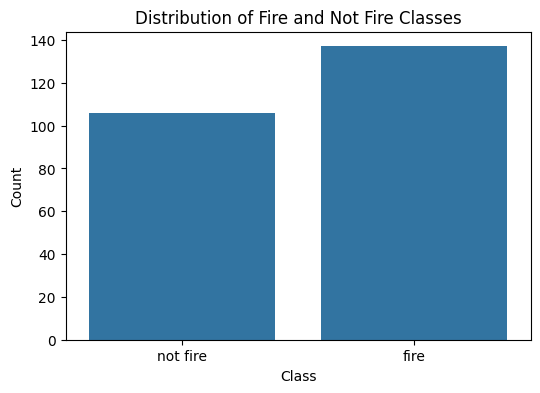

In [31]:
plt.figure(figsize=(6, 4))

sns.countplot(x="Classes", data=df)

plt.title("Distribution of Fire and Not Fire Classes")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

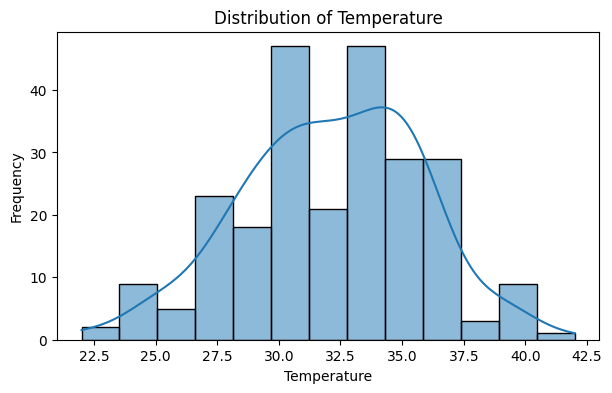

In [32]:
plt.figure(figsize=(7, 4))

sns.histplot(df["Temperature"], kde=True)

plt.title("Distribution of Temperature")
plt.xlabel("Temperature")
plt.ylabel("Frequency")

plt.show()

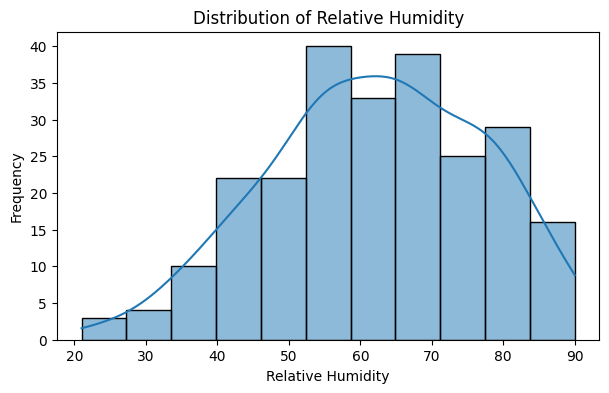

In [33]:
plt.figure(figsize=(7, 4))

sns.histplot(df["Relative Humidity"], kde=True)

plt.title("Distribution of Relative Humidity")
plt.xlabel("Relative Humidity")
plt.ylabel("Frequency")

plt.show()

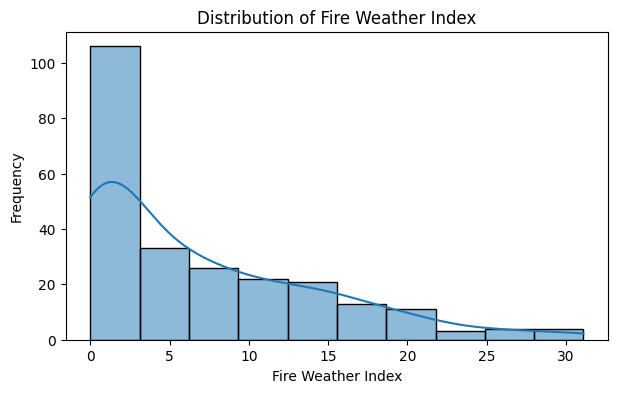

In [34]:
plt.figure(figsize=(7, 4))

sns.histplot(df["Fire Weather Index"], kde=True)

plt.title("Distribution of Fire Weather Index")
plt.xlabel("Fire Weather Index")
plt.ylabel("Frequency")

plt.show()

In [35]:
missing_row = {
    "Day": 14,
    "Month": 7,
    "Year": 2012,
    "Temperature": 37,
    "Relative Humidity": 37,
    "Wind Speed": 18,
    "Rain": 0.2,
    "Fine Fuel Moisture Code": 88.9,
    "Duff Moisture Code": 12.9,
    "Drought Code": 14.6,
    "Initial Spread Index": 9.0,
    "Buildup Index": 12.5,
    "Fire Weather Index": 10.4,
    "Classes": "fire"
}

# Prevent accidental duplication if this cell is run twice
condition = (
    (df["Day"] == 14) &
    (df["Month"] == 7) &
    (df["Temperature"] == 37) &
    (df["Relative Humidity"] == 37) &
    (df["Fire Weather Index"] == 10.4)
)

if not condition.any():
    df = pd.concat(
        [df, pd.DataFrame([missing_row])],
        ignore_index=True
    )

print("Final dataset shape:", df.shape)

print("\nClass Distribution:")
print(df["Classes"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Final dataset shape: (244, 14)

Class Distribution:
Classes
fire        138
not fire    106
Name: count, dtype: int64

Missing Values:
0

Duplicate Rows:
0


In [36]:
df.to_csv(
    "Algerian_Forest_Fires_Cleaned.csv",
    index=False
)

print("Final corrected dataset saved!")

Final corrected dataset saved!


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

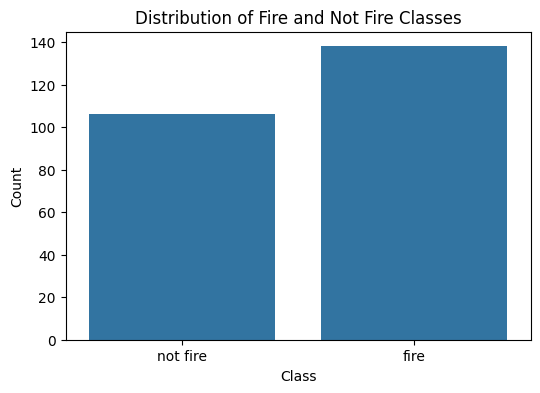

In [38]:
plt.figure(figsize=(6, 4))

sns.countplot(x="Classes", data=df)

plt.title("Distribution of Fire and Not Fire Classes")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

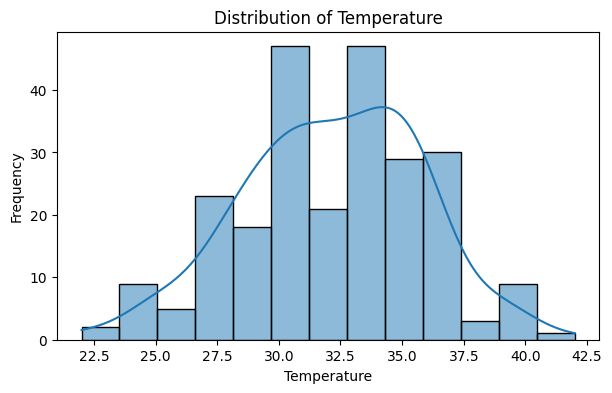

In [39]:
plt.figure(figsize=(7, 4))

sns.histplot(df["Temperature"], kde=True)

plt.title("Distribution of Temperature")
plt.xlabel("Temperature")
plt.ylabel("Frequency")

plt.show()

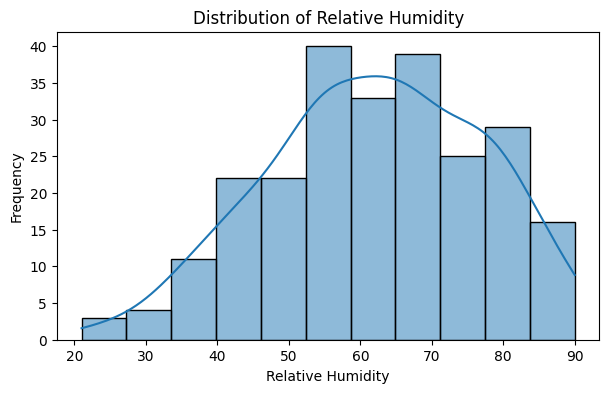

In [40]:
plt.figure(figsize=(7, 4))

sns.histplot(df["Relative Humidity"], kde=True)

plt.title("Distribution of Relative Humidity")
plt.xlabel("Relative Humidity")
plt.ylabel("Frequency")

plt.show()

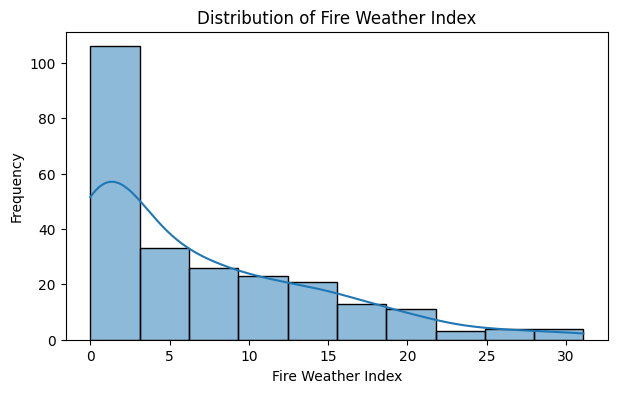

In [41]:
plt.figure(figsize=(7, 4))

sns.histplot(df["Fire Weather Index"], kde=True)

plt.title("Distribution of Fire Weather Index")
plt.xlabel("Fire Weather Index")
plt.ylabel("Frequency")

plt.show()

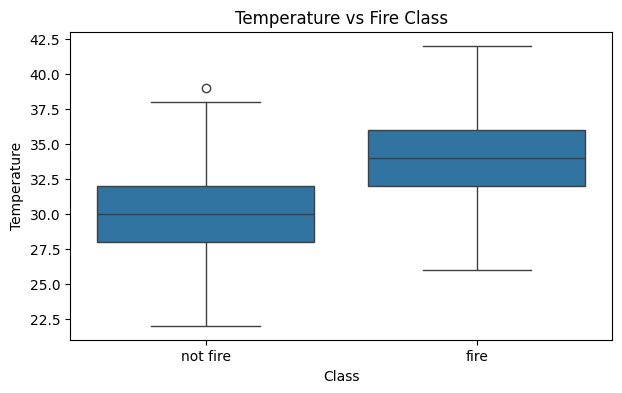

In [42]:
# Temperature vs Class
plt.figure(figsize=(7, 4))
sns.boxplot(x="Classes", y="Temperature", data=df)

plt.title("Temperature vs Fire Class")
plt.xlabel("Class")
plt.ylabel("Temperature")
plt.show()

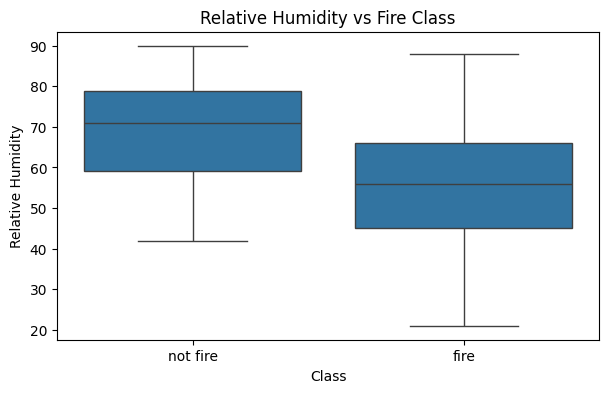

In [43]:
# Relative Humidity vs Class
plt.figure(figsize=(7, 4))
sns.boxplot(x="Classes", y="Relative Humidity", data=df)

plt.title("Relative Humidity vs Fire Class")
plt.xlabel("Class")
plt.ylabel("Relative Humidity")
plt.show()

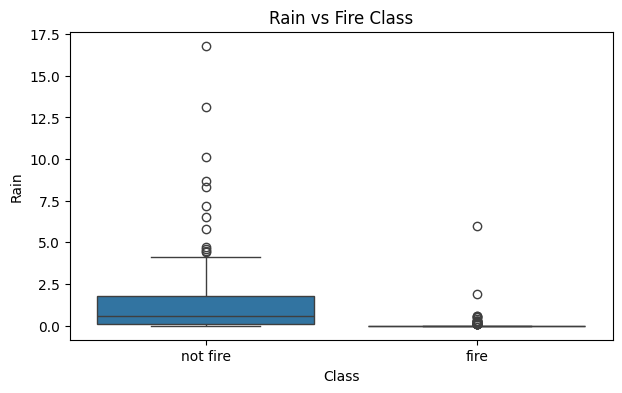

In [44]:
# Rain vs Class
plt.figure(figsize=(7, 4))
sns.boxplot(x="Classes", y="Rain", data=df)

plt.title("Rain vs Fire Class")
plt.xlabel("Class")
plt.ylabel("Rain")
plt.show()

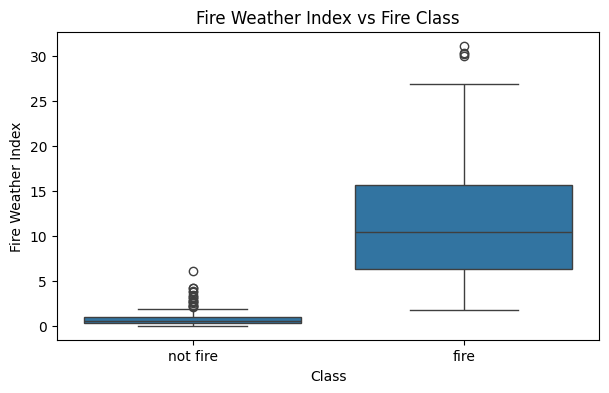

In [45]:
# Fire Weather Index vs Class
plt.figure(figsize=(7, 4))
sns.boxplot(x="Classes", y="Fire Weather Index", data=df)

plt.title("Fire Weather Index vs Fire Class")
plt.xlabel("Class")
plt.ylabel("Fire Weather Index")
plt.show()

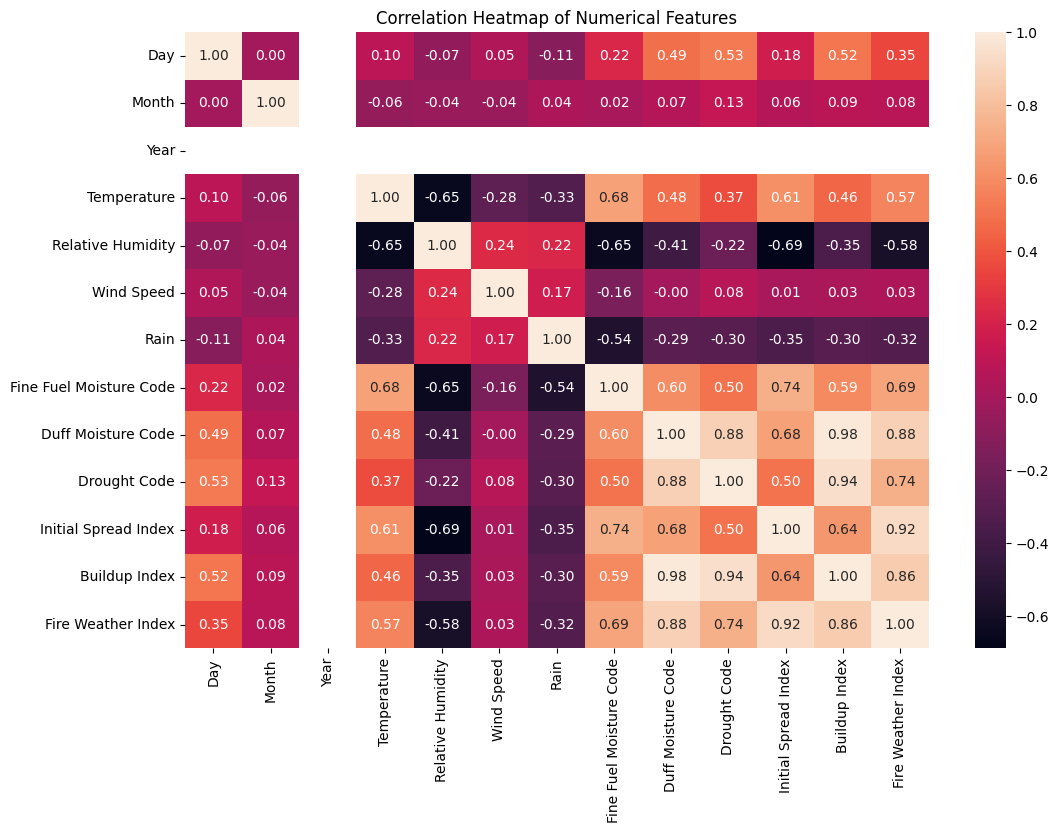

In [46]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=["int64", "float64"])

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [47]:
# Temporary numeric version of target for EDA only
df["Fire_Label"] = df["Classes"].map({
    "not fire": 0,
    "fire": 1
})

# Correlation of every numerical feature with the target
target_correlation = (
    df.select_dtypes(include="number")
      .corr()["Fire_Label"]
      .sort_values(ascending=False)
)

print("Correlation with Fire Class:")
print(target_correlation)

Correlation with Fire Class:
Fire_Label                 1.000000
Fine Fuel Moisture Code    0.770114
Initial Spread Index       0.736142
Fire Weather Index         0.719407
Buildup Index              0.584545
Duff Moisture Code         0.584188
Temperature                0.518119
Drought Code               0.507122
Day                        0.201784
Month                      0.022333
Wind Speed                -0.066529
Rain                      -0.379449
Relative Humidity         -0.435023
Year                            NaN
Name: Fire_Label, dtype: float64


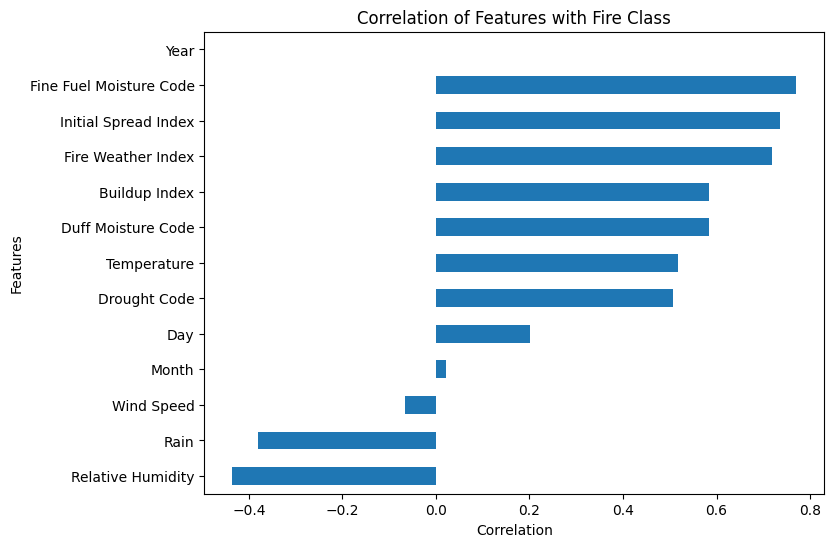

In [48]:
plt.figure(figsize=(8, 6))

target_correlation.drop("Fire_Label").sort_values().plot(
    kind="barh"
)

plt.title("Correlation of Features with Fire Class")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.show()

In [49]:
class_summary = df.groupby("Classes")[
    [
        "Temperature",
        "Relative Humidity",
        "Wind Speed",
        "Rain",
        "Fine Fuel Moisture Code",
        "Duff Moisture Code",
        "Drought Code",
        "Initial Spread Index",
        "Buildup Index",
        "Fire Weather Index"
    ]
].mean()

print(class_summary)

          Temperature  Relative Humidity  Wind Speed      Rain  \
Classes                                                          
fire        33.818841          56.275362   15.340580  0.097101   
not fire    30.028302          69.311321   15.716981  1.624528   

          Fine Fuel Moisture Code  Duff Moisture Code  Drought Code  \
Classes                                                               
fire                    87.544928           20.992754     70.409420   
not fire                65.315094            6.446226     21.790566   

          Initial Spread Index  Buildup Index  Fire Weather Index  
Classes                                                            
fire                  7.434783      23.934058           11.723188  
not fire              1.277358       7.220755            0.964151  


In [50]:
########################## FEATURE PREPARATION ###################################
# Check target encoding
print(df[["Classes", "Fire_Label"]].head(10))

    Classes  Fire_Label
0  not fire           0
1  not fire           0
2  not fire           0
3  not fire           0
4  not fire           0
5      fire           1
6      fire           1
7      fire           1
8  not fire           0
9  not fire           0


In [51]:
# Input features
X = df.drop(
    columns=[
        "Classes",
        "Fire_Label",
        "Year"
    ]
)

# Target
y = df["Fire_Label"]

print("Features used for prediction:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features used for prediction:
['Day', 'Month', 'Temperature', 'Relative Humidity', 'Wind Speed', 'Rain', 'Fine Fuel Moisture Code', 'Duff Moisture Code', 'Drought Code', 'Initial Spread Index', 'Buildup Index', 'Fire Weather Index']

X shape: (244, 12)
y shape: (244,)


In [52]:
############################# TRAIN/TEST-SPLIT ############################
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training features: (195, 12)
Testing features: (49, 12)

Training target: (195,)
Testing target: (49,)

Training class distribution:
Fire_Label
1    110
0     85
Name: count, dtype: int64

Testing class distribution:
Fire_Label
1    28
0    21
Name: count, dtype: int64


In [54]:
stratify=y

In [55]:
#################### TRAIN THE FIRST MODEL: Random Forest. ####################
######################## RANDOM FOREST MODEL ########################

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [56]:
# Predictions on test data
y_pred_rf = rf_model.predict(X_test)

# Predicted probabilities for ROC-AUC
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Performance")
print("-------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc_auc, 4))

Random Forest Performance
-------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0
ROC-AUC  : 1.0


In [58]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Not Fire", "Fire"]
    )
)

Classification Report:

              precision    recall  f1-score   support

    Not Fire       1.00      1.00      1.00        21
        Fire       1.00      1.00      1.00        28

    accuracy                           1.00        49
   macro avg       1.00      1.00      1.00        49
weighted avg       1.00      1.00      1.00        49



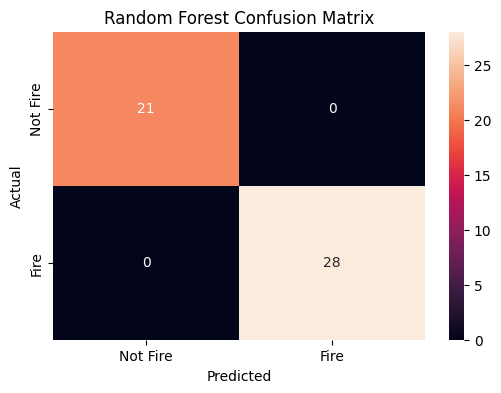

In [59]:
plt.figure(figsize=(6, 4))

cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    xticklabels=["Not Fire", "Fire"],
    yticklabels=["Not Fire", "Fire"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [60]:
#################### GRADIENT BOOSTING MODEL ####################

from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [61]:
# Predictions
y_pred_gb = gb_model.predict(X_test)

# Probabilities for ROC-AUC
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


In [62]:
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb)
gb_recall = recall_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)
gb_roc_auc = roc_auc_score(y_test, y_prob_gb)

print("Gradient Boosting Performance")
print("-----------------------------")
print("Accuracy :", round(gb_accuracy, 4))
print("Precision:", round(gb_precision, 4))
print("Recall   :", round(gb_recall, 4))
print("F1-Score :", round(gb_f1, 4))
print("ROC-AUC  :", round(gb_roc_auc, 4))

Gradient Boosting Performance
-----------------------------
Accuracy : 0.9592
Precision: 0.9333
Recall   : 1.0
F1-Score : 0.9655
ROC-AUC  : 0.9991


In [63]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_gb,
        target_names=["Not Fire", "Fire"]
    )
)

Classification Report:

              precision    recall  f1-score   support

    Not Fire       1.00      0.90      0.95        21
        Fire       0.93      1.00      0.97        28

    accuracy                           0.96        49
   macro avg       0.97      0.95      0.96        49
weighted avg       0.96      0.96      0.96        49



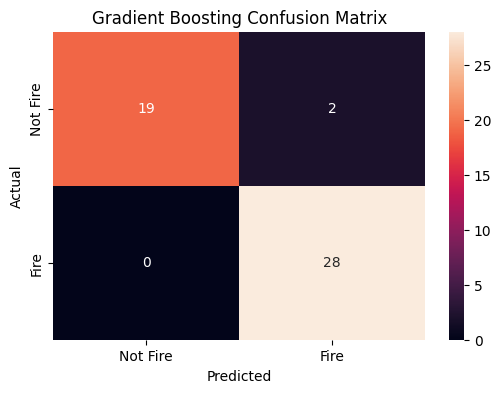

In [64]:
plt.figure(figsize=(6, 4))

cm_gb = confusion_matrix(y_test, y_pred_gb)

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    xticklabels=["Not Fire", "Fire"],
    yticklabels=["Not Fire", "Fire"]
)

plt.title("Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [65]:
#################### 5-FOLD CROSS VALIDATION ####################

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Random Forest cross-validation
rf_cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

# Gradient Boosting cross-validation
gb_cv_scores = cross_val_score(
    gb_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Random Forest Cross-Validation Scores:")
print(rf_cv_scores)

print("\nRandom Forest Mean Accuracy:")
print(round(rf_cv_scores.mean(), 4))

print("\nRandom Forest Standard Deviation:")
print(round(rf_cv_scores.std(), 4))


print("\n-----------------------------------")


print("\nGradient Boosting Cross-Validation Scores:")
print(gb_cv_scores)

print("\nGradient Boosting Mean Accuracy:")
print(round(gb_cv_scores.mean(), 4))

print("\nGradient Boosting Standard Deviation:")
print(round(gb_cv_scores.std(), 4))

Random Forest Cross-Validation Scores:
[0.95918367 1.         0.97959184 1.         0.95833333]

Random Forest Mean Accuracy:
0.9794

Random Forest Standard Deviation:
0.0184

-----------------------------------

Gradient Boosting Cross-Validation Scores:
[0.93877551 0.97959184 0.97959184 0.95918367 1.        ]

Gradient Boosting Mean Accuracy:
0.9714

Gradient Boosting Standard Deviation:
0.0208


In [66]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ],

    "Gradient Boosting": [
        gb_accuracy,
        gb_precision,
        gb_recall,
        gb_f1,
        gb_roc_auc
    ]
})

comparison = comparison.round(4)

print(comparison)

      Metric  Random Forest  Gradient Boosting
0   Accuracy            1.0             0.9592
1  Precision            1.0             0.9333
2     Recall            1.0             1.0000
3   F1-Score            1.0             0.9655
4    ROC-AUC            1.0             0.9991


In [67]:
#################### RANDOM FOREST FEATURE IMPORTANCE ####################

rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(rf_importance)

                    Feature  Importance
9      Initial Spread Index    0.342380
6   Fine Fuel Moisture Code    0.212927
11       Fire Weather Index    0.150114
10            Buildup Index    0.097059
7        Duff Moisture Code    0.069763
5                      Rain    0.054794
8              Drought Code    0.040271
2               Temperature    0.019320
3         Relative Humidity    0.005845
0                       Day    0.004226
4                Wind Speed    0.002195
1                     Month    0.001106


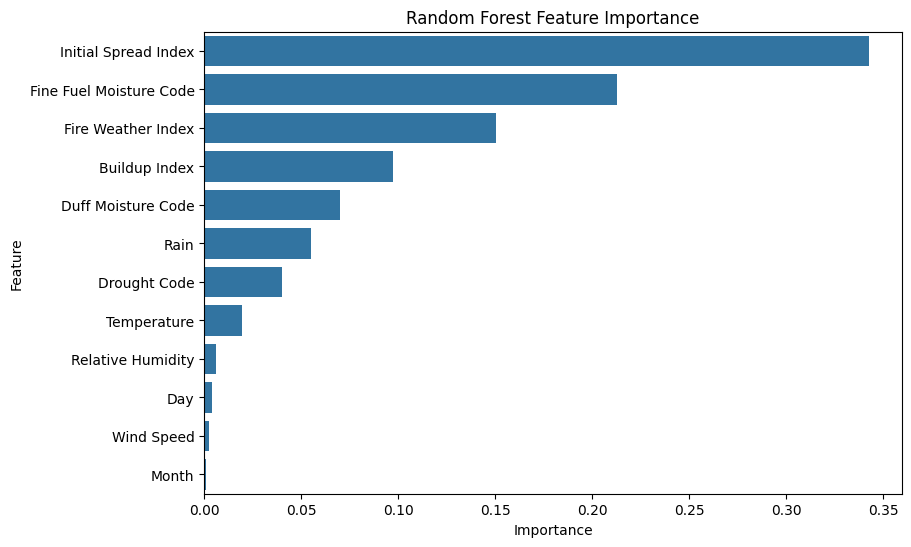

In [68]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [69]:
#################### GRADIENT BOOSTING FEATURE IMPORTANCE ####################

gb_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": gb_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(gb_importance)

                    Feature  Importance
9      Initial Spread Index    0.964166
6   Fine Fuel Moisture Code    0.015066
3         Relative Humidity    0.009033
0                       Day    0.005578
8              Drought Code    0.002322
7        Duff Moisture Code    0.002101
11       Fire Weather Index    0.000706
10            Buildup Index    0.000502
1                     Month    0.000356
2               Temperature    0.000171
4                Wind Speed    0.000000
5                      Rain    0.000000


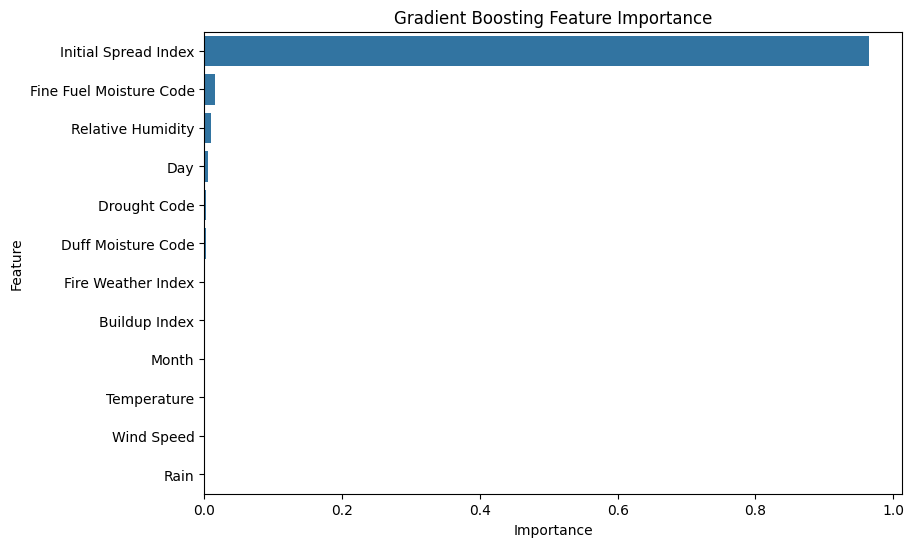

In [70]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=gb_importance,
    x="Importance",
    y="Feature"
)

plt.title("Gradient Boosting Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

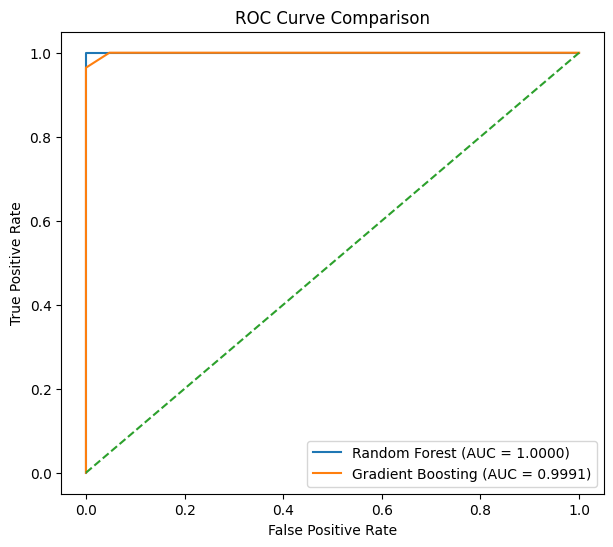

In [71]:
from sklearn.metrics import roc_curve

# Random Forest ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Gradient Boosting ROC
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_roc_auc:.4f})"
)

plt.plot(
    fpr_gb,
    tpr_gb,
    label=f"Gradient Boosting (AUC = {gb_roc_auc:.4f})"
)

# Random-classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [72]:
#################### FINAL RANDOM FOREST MODEL ####################

from sklearn.ensemble import RandomForestClassifier

final_rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

final_rf_model.fit(X, y)

print("Final Random Forest model trained on complete dataset!")

Final Random Forest model trained on complete dataset!


In [74]:
def predict_fire_risk(
    day,
    month,
    temperature,
    relative_humidity,
    wind_speed,
    rain,
    ffmc,
    dmc,
    dc,
    isi,
    bui,
    fwi
):

    input_data = pd.DataFrame([{
        "Day": day,
        "Month": month,
        "Temperature": temperature,
        "Relative Humidity": relative_humidity,
        "Wind Speed": wind_speed,
        "Rain": rain,
        "Fine Fuel Moisture Code": ffmc,
        "Duff Moisture Code": dmc,
        "Drought Code": dc,
        "Initial Spread Index": isi,
        "Buildup Index": bui,
        "Fire Weather Index": fwi
    }])

    prediction = final_rf_model.predict(input_data)[0]

    probability = final_rf_model.predict_proba(input_data)[0][1]

    if prediction == 1:
        result = "FIRE"
    else:
        result = "NOT FIRE"

    print("Prediction:", result)
    print("Estimated Fire Probability:", round(probability * 100, 2), "%")

    return result

In [75]:
predict_fire_risk(
    day=15,
    month=8,
    temperature=35,
    relative_humidity=45,
    wind_speed=15,
    rain=0,
    ffmc=90,
    dmc=25,
    dc=80,
    isi=10,
    bui=30,
    fwi=15
)

Prediction: FIRE
Estimated Fire Probability: 100.0 %


'FIRE'

In [76]:
predict_fire_risk(
    day=10,
    month=6,
    temperature=27,
    relative_humidity=80,
    wind_speed=12,
    rain=2.5,
    ffmc=55,
    dmc=4,
    dc=10,
    isi=0.5,
    bui=4,
    fwi=0.4
)

Prediction: NOT FIRE
Estimated Fire Probability: 0.0 %


'NOT FIRE'

In [77]:
import joblib

model_package = {
    "model": final_rf_model,
    "features": X.columns.tolist()
}

joblib.dump(
    model_package,
    "Forest_Fire_Random_Forest_Model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [78]:
import joblib

model_package = joblib.load(
    "Forest_Fire_Random_Forest_Model.pkl"
)

loaded_model = model_package["model"]
feature_names = model_package["features"]

print("Model loaded successfully!")

Model loaded successfully!


In [79]:
#################### USER INPUT FIRE RISK PREDICTION ####################

def user_fire_prediction():

    print("==========================================")
    print("       FOREST FIRE RISK PREDICTION")
    print("==========================================")

    day = int(input("Enter Day (1-31): "))
    month = int(input("Enter Month (6-9): "))

    temperature = float(input("Enter Temperature (°C): "))
    relative_humidity = float(input("Enter Relative Humidity (%): "))
    wind_speed = float(input("Enter Wind Speed: "))
    rain = float(input("Enter Rainfall: "))

    ffmc = float(input("Enter FFMC: "))
    dmc = float(input("Enter DMC: "))
    dc = float(input("Enter DC: "))
    isi = float(input("Enter ISI: "))
    bui = float(input("Enter BUI: "))
    fwi = float(input("Enter FWI: "))

    input_data = pd.DataFrame([{
        "Day": day,
        "Month": month,
        "Temperature": temperature,
        "Relative Humidity": relative_humidity,
        "Wind Speed": wind_speed,
        "Rain": rain,
        "Fine Fuel Moisture Code": ffmc,
        "Duff Moisture Code": dmc,
        "Drought Code": dc,
        "Initial Spread Index": isi,
        "Buildup Index": bui,
        "Fire Weather Index": fwi
    }])

    prediction = loaded_model.predict(input_data)[0]

    probability = loaded_model.predict_proba(input_data)[0][1]

    print("\n==========================================")

    if prediction == 1:
        print("Prediction: FIRE")
    else:
        print("Prediction: NOT FIRE")

    print(
        "Estimated Fire Probability:",
        round(probability * 100, 2),
        "%"
    )

    print("==========================================")

In [80]:
user_fire_prediction()

       FOREST FIRE RISK PREDICTION
Enter Day (1-31): 27
Enter Month (6-9): 8
Enter Temperature (°C): 34
Enter Relative Humidity (%): 50
Enter Wind Speed: 20
Enter Rainfall: 2
Enter FFMC: 100
Enter DMC: 33
Enter DC: 67
Enter ISI: 10
Enter BUI: 26
Enter FWI: 18

Prediction: FIRE
Estimated Fire Probability: 95.0 %
